# Логистическая регрессия

Напомним, что мы по-прежнему решаем задачу бинарной классификации, в которой целевая переменная $y$ принимает два значения: -1 и 1. На прошлом семинаре мы обсудили, что эту задачу можно решить при помощи линейного классификатора 

$$
f(x_i, w) = \mathrm{sign}\left(\langle x_i, w \rangle\right).
$$

Функция потерь для такой задачи – это сумма индикаторов того, что предсказание сделано неверно: 

$$Q(X, w) = \frac{1}{\ell}\sum_{i = 1}^{\ell}[y_i \ne \mathrm{sign}\left(\langle x_i, w \rangle\right)].$$

На лекциях мы обсуждали, что эту идею можно удобно записать через функцию отступа:

$$
Q(X, w) = \frac{1}{\ell}\sum_{i = 1}^{\ell}[y_i \langle x_i, w \rangle < 0].
$$

Такую функцию проблематично дифференцировать по $w$, потому что даже в местах, где градиент существует, он равен нулю. Вместо этого будем минимизировать некоторую функцию $\tilde{Q}(X, w)$, являющуюся верхней оценкой для $Q(X, w)$, и надеяться, что минимизация $\tilde{Q}(X, w)$ позволит достаточно хорошо минимизировать и $Q(X, w)$.

Логистическая регрессия предлагает использовать логистическую функцию потерь:

$$
\tilde{Q}(X, w) = \frac{1}{\ell}\sum_{i = 1}^{\ell}\log(1 + e^{-y_i \langle x_i, w \rangle}) \rightarrow \min_w.
$$

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

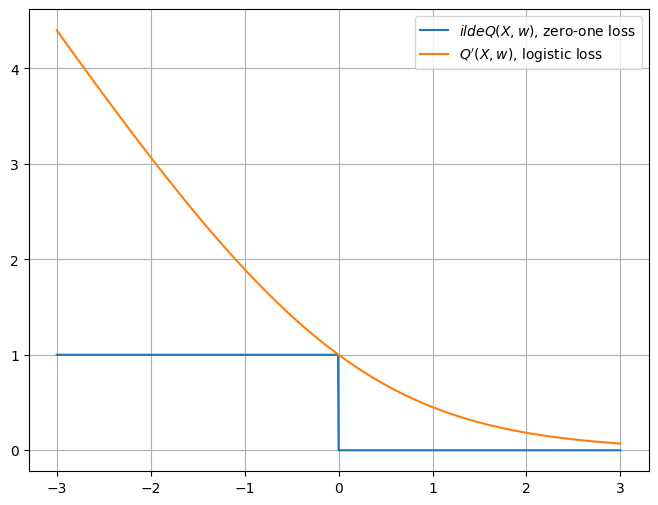

In [2]:
x = np.concatenate((np.linspace(-3, 0, 500), np.linspace(0, 3, 500)))
np.random.seed(123)
y = np.ones(1000)
w = np.ones(1000)
M = y * x * w

plt.figure(figsize = (8, 6))
plt.plot(x * w, x < 0, label = "$\tilde{Q}(X, w)$, zero-one loss")
plt.plot(M, np.log2(1 + np.exp(-M)), label = "$Q'(X, w)$, logistic loss")
plt.grid()
plt.legend();

Для получения классической задачи логистической регрессии остаётся сделать один шаг и немного изменить постановку задачи. Предположим, что мы хотим решать задачу **мягкой** классификации, то есть предсказывать не метку класса, а вероятность того, что наблюдение принадлежит к классу. Понятно, что мы всегда можем перейти от мягкой классификации к жёсткой, выбрав порог принадлежности к положительному классу. 

**Задание 1.** Поясните, почему для решения задачи мягкой классификации классификатор $f(x_i, w) = \left(\langle x_i, w \rangle\right)$ – не лучший выбор. 

**Ответ:**

Полученное скалярное произведение необязательно будет лежать в отрезке $[0, 1]$.

Мы можем решить названную проблему, подставив $\left(\langle x_i, w \rangle\right)$ в некоторую функцию, областью значений которой является промежуток от 0 до 1. В логистической регрессии такой функцией выступает **сигмоида**:

$$
\sigma(x) = \dfrac{e^x}{1 + e^x} = \dfrac{1}{1 + e^{-x}}.
$$

**Задание 2.** Сигмоида обалдает замечательным свойством, которое значительно упрощает вычисление градиентов при градиентном спуске:

$$
\sigma(x)'_x = \sigma(x)(1 - \sigma(x)). 
$$

Покажите, что это действительно так.

**Решение:**

$$
\sigma(x)' = \frac{e^x(1 + e^x) - e^{2x}}{(1 + e^x)^2} = \frac{e^x}{1 + e^x}\frac{1}{1 + e^x} = \sigma(x)(1-\sigma(x)).
$$

Путём хитрых математических преобразований можно показать, что при использовании сигмоиды (= при решении задачи мягкой классификации) $\tilde{Q}(X, w)$ можно записать в следующем виде:

$$
\tilde{Q}(X, w) = -\frac{1}{\ell} \sum_{i=1}^{\ell} [y_i = 1]\log\sigma(\langle x_i, w \rangle) + [y_i = -1]\log(1-\sigma(\langle x_i, w \rangle)
$$

Эта функция называется log-loss или кросс-энтропией между истинной целевой переменной и предсказанными вероятностями.

**А почему? А потому:**

$$
\tilde{Q}(X, w) = -\frac{1}{\ell} \sum_{i=1}^{\ell} [y_i = 1]\log\sigma(\langle x_i, w \rangle) + [y_i = -1]\log(1-\sigma(\langle x_i, w \rangle) =\\
$$
$$
=-\frac{1}{\ell} \sum_{i=1}^{\ell} [y_i = 1]\log\left(\frac{1}{1 + e^{-\langle x_i, w\rangle}}\right) + [y_i = -1](\log\left(1-\frac{1}{1 + e^{-\langle x_i, w\rangle}}\right)) =\\
$$
$$
=-\frac{1}{\ell} \sum_{i=1}^{\ell} [y_i = 1]\log\left(\frac{1}{1 + e^{-\langle x_i, w\rangle}}\right) + [y_i = -1](\log\left(\frac{1}{1 + e^{\langle x_i, w\rangle}}\right)) =\\
$$
$$
=\frac{1}{\ell} \sum_{i=1}^{\ell} [y_i = 1]\log(1 + e^{-\langle x_i, w \rangle}) + [y_i = -1]\log(1 + e^{\langle x_i, w \rangle}) =\\
$$
$$
=\frac{1}{\ell} \sum_{i=1}^{\ell}\log(1 + e^{-y_i\langle x_i, w\rangle}) = \tilde{Q}(X, w)
$$

Регуляризация вводится таким же образом, как это было в случае линейной регрессии. Например, функция потерь для $\ell$-$2$ регуляризации выглядит так:

$$
\tilde{Q}_{reg}(X, w) = \tilde{Q}(X, w) + \frac{1}{2}\lambda\|w\|^2_2.
$$

**Саммари по логистической регрессии:**

- Данные: $y_i \in \{-1, 1\}$, $X$

- Предсказания:

    - По умолчанию предсказывает вероятности:
    $$
    \hat{p}_i = \sigma(\langle x_i, w\rangle) = \frac{1}{1 + e^{-\langle x_i, w\rangle}}
    $$
    
    - Если хотим перейти к метке, то сравниваем вероятность с порогом $t$:
    
    $$
    \hat{y}_i = \begin{cases}
    1,&\text{ если } \hat{p}_i > t,\\
    -1,&\text{ иначе.}
    \end{cases}
    $$
    
- Обучение: 

$$
\tilde{Q}(X, w) = -\frac{1}{\ell} \sum_{i=1}^{\ell} [y_i = 1]\log\sigma(\langle x_i, w \rangle) + [y_i = -1]\log(1-\sigma(\langle x_i, w \rangle) \to \min_w
$$

## Калибровка вероятностей

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from scipy.special import expit

sns.set_style('whitegrid')
plt.rcParams.update({'font.size': 14})


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/traitlets/config/application.py", line 1043, in launch_instance
    app.start()
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/ipyk

AttributeError: _ARRAY_API not found

В этом задании мы будем использовать [данные](https://www.kaggle.com/mssmartypants/rice-type-classification) о бинарной классификации риса.

In [2]:
#%%bash
#kaggle datasets download -d mssmartypants/rice-type-classification
#unzip -qq rice-type-classification.zip

In [3]:
data = pd.read_csv('riceClassification.csv')
data

,id,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,1,4537,92.229316,64.012769,0.719916,4677,76.004525,0.657536,273.085,0.764510,1.440796,1
1,2,2872,74.691881,51.400454,0.725553,3015,60.471018,0.713009,208.317,0.831658,1.453137,1
2,3,3048,76.293164,52.043491,0.731211,3132,62.296341,0.759153,210.012,0.868434,1.465950,1
3,4,3073,77.033628,51.928487,0.738639,3157,62.551300,0.783529,210.657,0.870203,1.483456,1
4,5,3693,85.124785,56.374021,0.749282,3802,68.571668,0.769375,230.332,0.874743,1.510000,1
...,...,...,...,...,...,...,...,...,...,...,...,...
18180,18181,5853,148.624571,51.029281,0.939210,6008,86.326537,0.498594,332.960,0.663444,2.912535,0
18181,18182,7585,169.593996,58.141659,0.939398,7806,98.272692,0.647461,385.506,0.641362,2.916910,0
18182,18183,6365,154.777085,52.908085,0.939760,6531,90.023162,0.561287,342.253,0.682832,2.925396,0
18183,18184,5960,151.397924,51.474600,0.940427,6189,87.112041,0.492399,343.371,0.635227,2.941216,0


Отмасштабируем данные и разделим на обучение и тест.

In [4]:
X = data.drop(columns=['id', 'Class'])
y = data.Class

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.4, random_state = 999)
scaler = StandardScaler().fit(X_train, y_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

Посмотрим на баланс классов в данных.

In [5]:
print('Class balance:', y.mean())

Class balance: 0.5490789111905416


Классы можно назвать сбалансированными. Обучим метод опорных векторов (SVC &mdash; Support Vector Classification) и логистическую регрессию, в качестве метрики возьмем ROC-AUC. В качестве скоров будем рассматривать выход `decision_function`, который пропорционален расстоянию до разделяющей гиперплоскости, взятого со знаком.

In [6]:
svc = LinearSVC(max_iter=100000, C=0.1).fit(X_train, y_train)
svc_pred = svc.decision_function(X_test)
print('SVC ROC-AUC:', roc_auc_score(y_test, svc_pred))

SVC ROC-AUC: 0.9991453206707389


In [7]:
lr = LogisticRegression(max_iter = 100000, C = 0.1).fit(X_train, y_train)
lr_pred = lr.decision_function(X_test)
print('Logistic regression ROC-AUC:', roc_auc_score(y_test, lr_pred))

Logistic regression ROC-AUC: 0.9990017675125695


ROC-AUC показывает, что мы практически идеально предсказываем целевую переменную. Посмотрим теперь на распределение скоров для тестовых объектов.

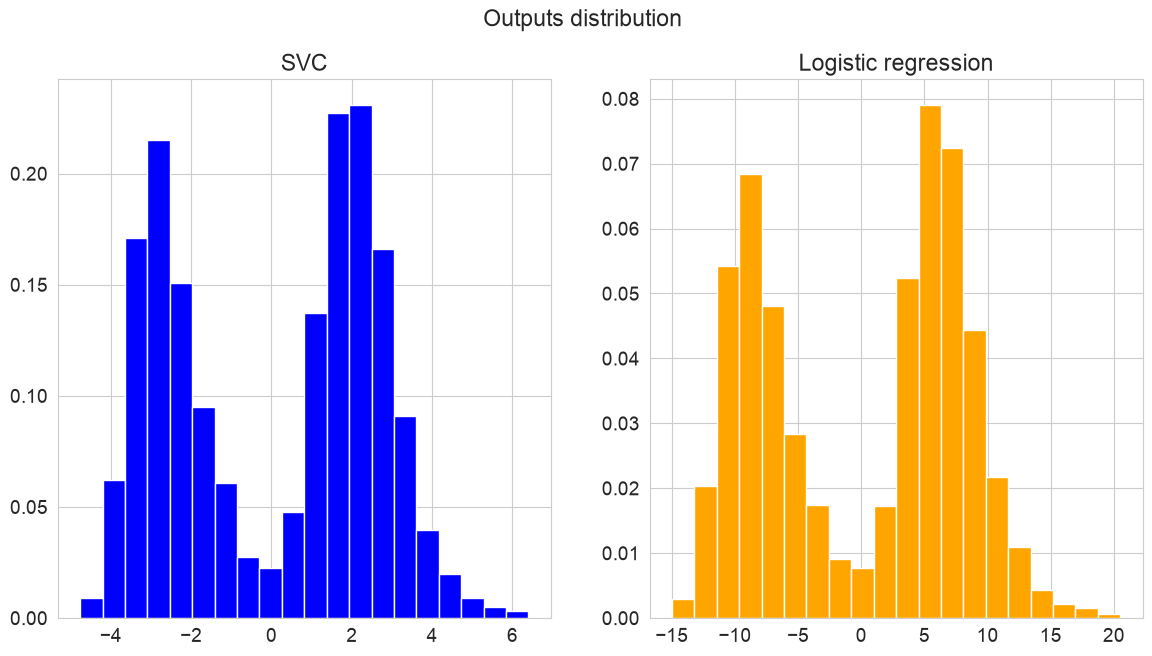

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(14, 7))

axs[0].hist(svc_pred, bins=20, color='blue', density='True')
axs[1].hist(lr_pred, bins=20, color='orange', density='True')

axs[0].set_title('SVC')
axs[1].set_title('Logistic regression')

plt.suptitle('Outputs distribution')
plt.show()

Мы видим, что скоры могут принимать любые вещественные значения. Но для оценивания вероятностей нам нужно загнать их в промежуток $[0, 1]$. Для логистической регрессии мы можем навесить сигмоиду, ведь модель и обучалась так, чтобы значение $\sigma\big(\langle w, x \rangle + b\big)$ приближало вероятности. Для SVC у нас нет такой опции, поэтому воспользуемся масштабированием через минимум-максимум.

In [9]:
svc_pred = (svc_pred - svc_pred.min()) / (svc_pred.max() - svc_pred.min())
lr_pred = lr.predict_proba(X_test)[:, 1]

In [10]:
lr_pred

array([0.99992478, 0.99762516, 0.99571443, ..., 0.82706601, 0.99978938,
       0.00104454], shape=(7274,))

Теперь мы можем построить калибровочные кривые.

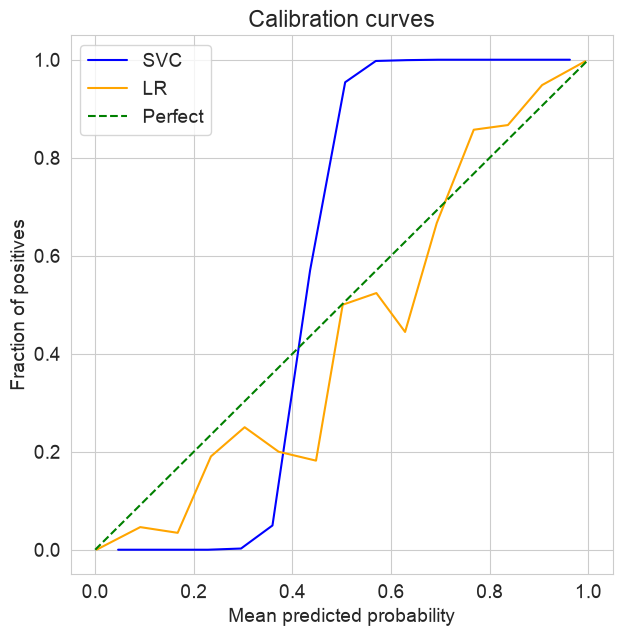

In [11]:
plt.figure(figsize=(7, 7))

svc_true_prob, svc_pred_prob = calibration_curve(y_test, svc_pred, n_bins=15)
lr_true_prob, lr_pred_prob = calibration_curve(y_test, lr_pred, n_bins=15)

plt.plot(svc_pred_prob, svc_true_prob, label='SVC', color='blue')
plt.plot(lr_pred_prob, lr_true_prob, label='LR', color='orange')
plt.plot([0, 1], [0, 1], label='Perfect', linestyle='--', color='green')

plt.xlabel('Mean predicted probability')
plt.ylabel('Fraction of positives')
plt.title('Calibration curves')
plt.legend()
plt.show()

Мы видим, что кривая для логистической регрессии неплохо приближает диагональ. То же самое, увы, нельзя сказать про SVC. Попробуем откалибровать классификаторы и построить новые кривые.

### Методы калибровки

Наиболее популярными являются два метода калибровки &mdash; калибровка Платта (сигмоидная) и изотоническая регрессия. Оба этих метода реализованы в [`sklearn`](https://scikit-learn.org/stable/modules/calibration.html#calibration).

**Калибровка Платта**

Допустим, у нас есть обученный класификатор $b(x)$, который выдает уверенность (скор) в том, что $x$ относится к положительному классу. Метод приближает вероятность положительного класса с помощью сигмоидной функции:

$$
p\big(y = +1 \big| b(x)\big) = \frac{1}{1 + \exp (A \cdot b(x) + C)}
$$

Здесь обучаемыми параметрами являются $A, C \in \mathbb{R}$, их подбирают с помощью метода максимального правдоподобия (точно так же, как в логистической регрессии). Сделать это можно по кросс-валидации или на отложенной выборке. 

**Изотоническая регрессия**

Другой метод использует так называемую изотоническую функцию &mdash; кусочно-линейную возрастающую функцию $f: \mathbb{R} \rightarrow \mathbb{R}$. Функция подбирается так, чтобы минимизировать MSE по выборке:

$$
\frac{1}{\ell} \sum_{i=1}^\ell \big(y_i - f(b(x_i))\big)^2 \rightarrow \min_f
$$

Этот метод склонен к переобучению, поэтому его рекомендуется применять только для больших выборок.

Мы будем подбирать параметры калибровки с помощью кросс-валидации. Конечно, нет большого смысла калибровать логистическую регрессию, но мы проведем небольшой эксперимент.

In [12]:
sigmoid_svc = CalibratedClassifierCV(svc, cv=3, method='sigmoid').fit(X_train, y_train)
sigmoid_svc_pred = sigmoid_svc.predict_proba(X_test)[:, 1]
print('SVC ROC-AUC:', roc_auc_score(y_test, sigmoid_svc_pred))

SVC ROC-AUC: 0.9991337204155334


In [13]:
isotonic_svc = CalibratedClassifierCV(svc, cv=3, method='isotonic').fit(X_train, y_train)
isotonic_svc_pred = isotonic_svc.predict_proba(X_test)[:, 1]
print('SVC ROC-AUC:', roc_auc_score(y_test, isotonic_svc_pred))

SVC ROC-AUC: 0.9990992249197903


In [14]:
sigmoid_lr = CalibratedClassifierCV(lr, cv=3, method='sigmoid').fit(X_train, y_train)
sigmoid_lr_pred = sigmoid_lr.predict_proba(X_test)[:, 1]
print('Logistic regression ROC-AUC:', roc_auc_score(y_test, sigmoid_lr_pred))

Logistic regression ROC-AUC: 0.9989783380497528


In [15]:
isotonic_lr = CalibratedClassifierCV(lr, cv=3, method='isotonic').fit(X_train, y_train)
isotonic_lr_pred = isotonic_lr.predict_proba(X_test)[:, 1]
print('Logistic regression ROC-AUC:', roc_auc_score(y_test, isotonic_lr_pred))

Logistic regression ROC-AUC: 0.9989381569026097


Построим новые калибровочные кривые:

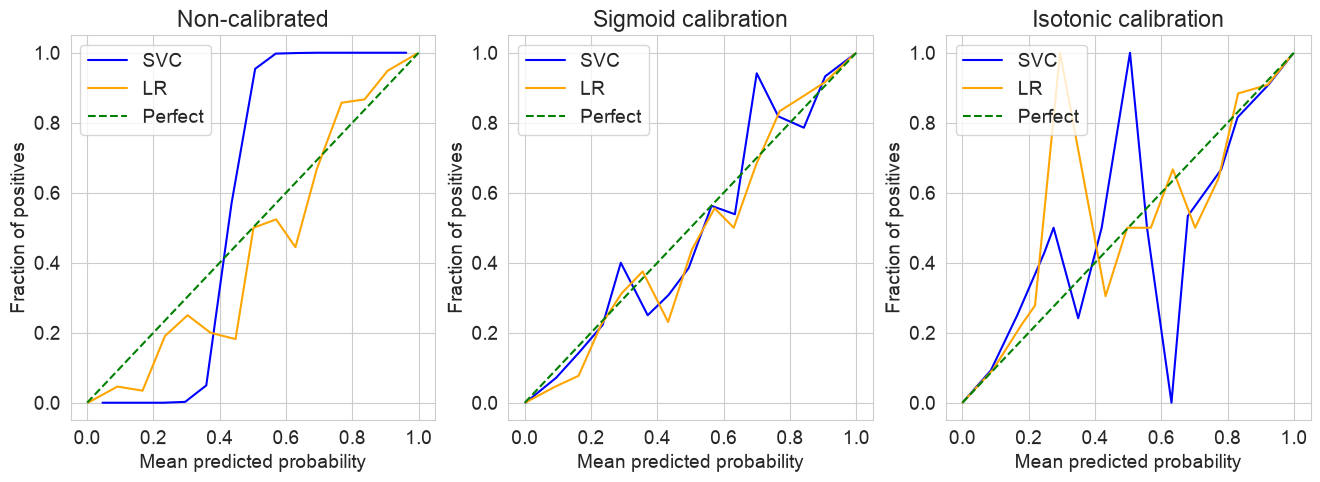

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5))

svc_true_prob, svc_pred_prob = calibration_curve(y_test, svc_pred, n_bins=15)
lr_true_prob, lr_pred_prob = calibration_curve(y_test, lr_pred, n_bins=15)

axs[0].plot(svc_pred_prob, svc_true_prob, label='SVC', color='blue')
axs[0].plot(lr_pred_prob, lr_true_prob, label='LR', color='orange')
axs[0].plot([0, 1], [0, 1], label='Perfect', linestyle='--', color='green')
axs[0].set_title('Non-calibrated')

svc_true_prob, svc_pred_prob = calibration_curve(y_test, sigmoid_svc_pred, n_bins=15)
lr_true_prob, lr_pred_prob = calibration_curve(y_test, sigmoid_lr_pred, n_bins=15)

axs[1].plot(svc_pred_prob, svc_true_prob, label='SVC', color='blue')
axs[1].plot(lr_pred_prob, lr_true_prob, label='LR', color='orange')
axs[1].plot([0, 1], [0, 1], label='Perfect', linestyle='--', color='green')
axs[1].set_title('Sigmoid calibration')

svc_true_prob, svc_pred_prob = calibration_curve(y_test, isotonic_svc_pred, n_bins=15)
lr_true_prob, lr_pred_prob = calibration_curve(y_test, isotonic_lr_pred, n_bins=15)

axs[2].plot(svc_pred_prob, svc_true_prob, label='SVC', color='blue')
axs[2].plot(lr_pred_prob, lr_true_prob, label='LR', color='orange')
axs[2].plot([0, 1], [0, 1], label='Perfect', linestyle='--', color='green')
axs[2].set_title('Isotonic calibration')

for ax in axs:
    ax.set_xlabel('Mean predicted probability')
    ax.set_ylabel('Fraction of positives')
    ax.legend()

plt.show()

Как мы видим, калибровка Платта действительно улучшила вероятности, который получаются у SVC. При этом кривая для логистической регрессии практически не сдвигается. В то же время, изотоническая регрессия немного подпортила эту кривую. Судя по всему, этот метод немного переобучился, хоть у нас и есть достаточно большая выборка.